In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm, multivariate_normal, truncnorm

In [2]:
rng = np.random.default_rng(0)

""" 
the first problem: take N gaussians with randomly sample (mean, var) from a range. 
Aggregation: Do a basic convolution and k-level minowski sum of the N distributions to get the aggregated Nagg gaussian
Disaggregation: Corresponding to Nagg distribution, select a random ref <= Some mathematical operation(Nagg) which will be the reference (target satisfaction score)
The disaggregation policy (implemented different methods): Over N_T horizon, we run t trials (sum(t) = N_T) to get S score in each trial. The objective of the complete trial using any policy is to satify this condition with 90% confidence level. 
P(sum(score)_t >= total_satisfaction_score) >= 90% 
The score in trials and as the reference are representative of power (say, 1 score represents 1 MW/some power unit * t). Assume the N assets don't deplete, don't change distribution, the first pull doesnot affect the second pull etc. Under this case, Greedy, UCB or Thompsons should give quite large scores to reach satisfaction and the point of the problem is to just see which arms the policy pulls through N_T
A bandit pulls one arm per trial; 
"""

" \nthe first problem: take N gaussians with randomly sample (mean, var) from a range. \nAggregation: Do a basic convolution and k-level minowski sum of the N distributions to get the aggregated Nagg gaussian\nDisaggregation: Corresponding to Nagg distribution, select a random ref <= Some mathematical operation(Nagg) which will be the reference (target satisfaction score)\nThe disaggregation policy (implemented different methods): Over N_T horizon, we run t trials (sum(t) = N_T) to get S score in each trial. The objective of the complete trial using any policy is to satify this condition with 90% confidence level. \nP(sum(score)_t >= total_satisfaction_score) >= 90% \nThe score in trials and as the reference are representative of power (say, 1 score represents 1 MW/some power unit * t). Assume the N assets don't deplete, don't change distribution, the first pull doesnot affect the second pull etc. Under this case, Greedy, UCB or Thompsons should give quite large scores to reach satisfa

In [3]:
mu_base = 50; sd_base = 50; lb = 0; ub = 100
a, b =  (lb-mu_base)/sd_base, (ub - mu_base)/sd_base
base = truncnorm(a, b, loc = mu_base, scale = sd_base) #range of EV soc

N = 10
mu = base.rvs(size = N, random_state = rng)
# sd = rng.uniform(2, 15, size = N)
sd = np.exp(rng.uniform(np.log(1), np.log(20), size = N))

arms = [truncnorm((lb-mu[i])/sd[i], (ub-mu[i])/sd[i], loc = mu[i], scale = sd[i]) for i in range(N)] #truncate all N to (0,100)


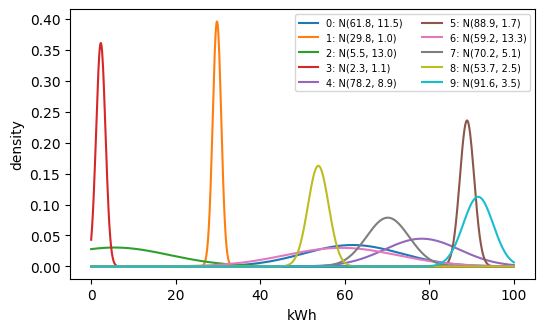

In [4]:
x = np.linspace(lb, ub, 1000)

plt.figure(figsize = (6, 3.5))
for i in range(N):
    plt.plot(x, norm.pdf(x, mu[i], sd[i]), label = f'{i}: N({mu[i]:.1f}, {sd[i]:.1f})')

plt.xlabel('kWh'); plt.ylabel('density'); plt.legend(fontsize = 7, ncol = 2)
plt.show()

In [5]:
from sklearn.mixture import GaussianMixture

def combine_sum(mu, var):                     #convolution: variances ADD
    return mu.sum(), var.sum()

def combine_weighted(mu, var, a):             #a = 1/N -> averaging, variance shrinks
    return (a * mu).sum(), (a**2 * var).sum()

def combine_product(mu, var):                 #fusion: precisions ADD, sharpens
    prec = 1 / var
    var_star = 1 / prec.sum()
    mu_star  = var_star * (mu * prec).sum()
    return mu_star, var_star

def build_mixture(mu, sigma, w):              #densities ADD, NOT gaussian
    var = sigma**2
    gmm = GaussianMixture(n_components = len(mu), covariance_type = "full")
    gmm.weights_      = w                     #inject known params instead of fitting
    gmm.means_        = mu.reshape(-1, 1)
    gmm.covariances_  = var.reshape(-1, 1, 1)
    gmm.precisions_cholesky_ = np.linalg.cholesky(np.linalg.inv(gmm.covariances_))

    mean = (w * mu).sum()
    total_var = (w * var).sum() + (w * (mu - mean)**2).sum()   #within + between
    return gmm, mean, total_var

1. sum                 mean =   541.13   sd =  24.65
2. weighted (a=1/N)    mean =    54.11   sd =   2.47
3. product             mean =    33.62   sd =   0.64
4. mixture             mean =    54.11   sd =  31.29


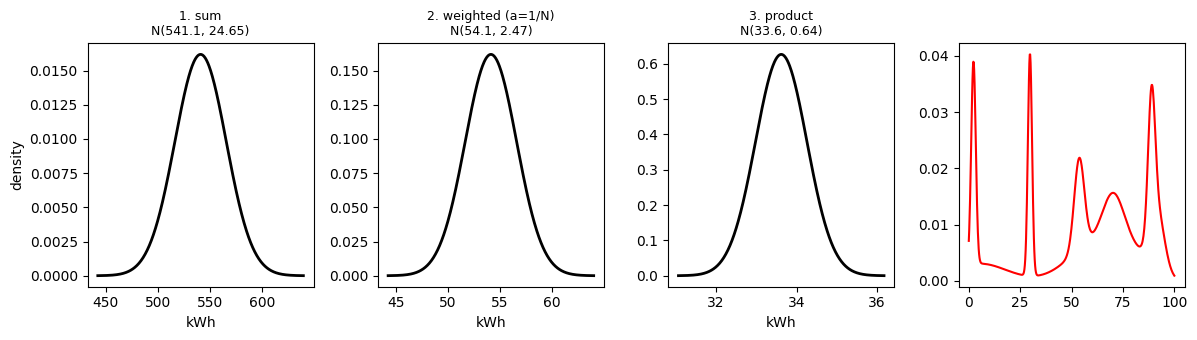

In [6]:
sigma = sd; var = sigma**2
w = np.full(N, 1/N)

m1, v1 = combine_sum(mu, var)
m2, v2 = combine_weighted(mu, var, w)
m3, v3 = combine_product(mu, var)
gmm, m4, v4 = build_mixture(mu, sigma, w)

res = [('1. sum', m1, v1), ('2. weighted (a=1/N)', m2, v2), ('3. product', m3, v3), ('4. mixture', m4, v4)]
for name, m, v in res: print(f'{name:<22} mean = {m:8.2f}   sd = {np.sqrt(v):6.2f}')

fig, ax = plt.subplots(1, 4, figsize = (12, 3.5))
for k, (name, m, v) in enumerate(res):
    s = np.sqrt(v)
    xx = np.linspace(m - 4*s, m + 4*s, 500)
    if k != 3:
        ax[k].plot(xx, norm.pdf(xx, m, s), 'k', lw = 2)
        ax[k].set_title(f'{name}\nN({m:.1f}, {s:.2f})', fontsize = 9); ax[k].set_xlabel('kWh')

xx = np.linspace(lb, ub, 500)                       #mixture is not gaussian -> overlay true density
ax[3].plot(xx, sum(w[i] * norm.pdf(xx, mu[i], sigma[i]) for i in range(N)), 'r', lw = 1.5)
ax[0].set_ylabel('density'); plt.tight_layout(); plt.show()

In [7]:
# assuming convolution of N gaussians is the aggregation

mu_agg, sd_agg = mu.sum(), sd.sum()           #Nagg, correlated


P90_Z = norm.ppf(0.10, mu_agg, sd_agg)                                #what the fleet clears w.p. 90%


Nref = P90_Z * rng.beta(5, 1.5)                                       #left-skewed -> mass close to cap

print(f'Nagg = N({mu_agg:.1f}, {sd_agg:.1f})   P10_Z = {P90_Z:.1f}')
print(f'Nref = {Nref:.1f}   ->  P(Nagg >= Nref) = {1 - norm.cdf(Nref, mu_agg, sd_agg):.3f}')

Nagg = N(541.1, 61.6)   P10_Z = 462.2
Nref = 407.8   ->  P(Nagg >= Nref) = 0.985


In [17]:
rate = 100           #P, kW discharge limit per EV
dt = 15/60           #15 min steps
NT = 5              #T_H, horizon in hours
T = int(NT/dt)      #steps
k = N               #EVs dispatched per step
alpha = 0.10        #1-alpha confidence

de_step = rate * dt         #max kWh per EV per step
de_max  = rate * NT         #max kWh per EV over horizon
eta = de_max / mu           #per-EV depletion ratio; >=1 means it can run dry

In [18]:
rho = 0.999                                         # positive semi definite -1/(n-1) < rho < 1.
Corr = np.full((N, N), rho); np.fill_diagonal(Corr, 1)
Sigma = np.outer(sd, sd) * Corr                        #Sigma_ij = rho.sd_i.sd_j, diag = sd^2

# create a multivariate distribution
X = multivariate_normal(mu, Sigma)
mu_Z, var_Z = mu.sum(), Sigma.sum()         # the mu and var of the Z 
sd_Z = np.sqrt(var_Z)    
Z = norm(mu_Z, sd_Z)

In [19]:
mu_E, sd_E = mu.sum(), sd.sum()   
Eagg = norm(mu_E, sd_E)    #stock: kWh stored in the fleet (Sum of marginals)

sum_p90_Xi = sum(norm.ppf(0.90, mu[i], sd[i]) for i in range(N))  # sum of marginal P90

trueEagg = Z # linear sum of multivariate X incl covar term
P90_Z = Z.ppf(0.9)

# 90% stored energy mass 
R_Xi = sum_p90_Xi
R_Z = P90_Z

# Reference
R = np.minimum(rate * NT * N, R_Z) # should it be P90_Z or P90_Xi?


In [20]:
L = np.linalg.cholesky(Corr)                                    # Corr, not Sigma — copula runs on correlation, not covariance
draws = L @ np.random.default_rng(100).standard_normal((N, 20000))   # correlated standard normals
U = norm.cdf(draws)                                                  # correlated uniforms, corr structure preserved
Es = np.array([arms[i].ppf(U[i]) for i in range(N)])             # (N, 20000), each row in [0,100], correlated across EVs

Cs = np.minimum(de_max, Es).sum(axis = 0) 

In [21]:
jt = np.random.default_rng(5).integers(Es.shape[1])
e_true = Es[:, jt].copy()   #hidden truth = one drawn scenario
Es = np.delete(Es, jt, axis = 1); Cs = np.delete(Cs, jt)                         #and it is no longer a candidate scenario
C_true = np.minimum(de_max, e_true).sum()       #available dispatch energy, unknown


In [22]:
print(f'T = {T} steps   de_step = {de_step:.3f} kWh   de_max = {de_max:.1f} kWh')
print(f'eta  : min {eta.min():.2f}  max {eta.max():.2f}   frac >= 1 : {(eta >= 1).mean():.2f}')
print(f'Xi = N({mu_E:.1f}, {sd_E:.5f}); \nZ = N({mu_Z:.1f}, {sd_Z:.5f});  \nC = {Cs.mean():.1f} +- {Cs.std():.1f} flow')
print(f'R_Xi = {R_Xi:.5f}  R_Z = {R_Z:.5f}  C_true = {C_true:.5f}   \nC_true - R_Z= {C_true - R_Z:.5f} -ve means there will be shortage')

T = 20 steps   de_step = 25.000 kWh   de_max = 500.0 kWh
eta  : min 5.46  max 219.34   frac >= 1 : 1.00
Xi = N(541.1, 61.61178); 
Z = N(541.1, 61.58590);  
C = 549.0 +- 56.6 flow
R_Xi = 620.09010  R_Z = 620.05693  C_true = 577.50865   
C_true - R_Z= -42.54828 -ve means there will be shortage


In [15]:
X

In [ ]:
# Policy - Greedy - draw one arm at a time. MAB dispatch
k = N # number of arms
epsilon = 0.1

def greedy_dispatch(t, D, available):
    ask = R - D.sum()
    
    
    
def run(policy, e0):
    e = e0.copy() #prior scernario (unknown)
    D = np.zeros(N) #delivery amount
    available = np.ones(N, bool) # available arms
    log = np.zeros((T, N))
    for t in range(T):
        if D.sum() >= R: break
        for i in policy(t, D, available):
            

In [16]:
np.random.random() 

0.536469293543643

In [ ]:
# Policy 1: Greedy
# Split the total requested reference by each time step and by each ev share.
# pace  : per-step need = remaining reference / remaining steps -> how many EVs to dispatch
# order : most-full-first on posterior mean remaining -> which EVs, keeps the small ones alive

k = N
def greedy_proportional(D, alive, t, S):
    need = (R - S) / (T - t)                            
    n = int(np.clip(np.ceil(need / de_step), 0, k))     #EVs needed, capped by k
    s = truncnorm.mean((D - mu)/sd, (ub - mu)/sd, loc = mu, scale = sd) - D #E[E0 | E0 >= D] - D, belief = prior truncated below at D
    s[~alive] = -np.inf
    return np.argsort(-s)[:n]

def greedy(D, alive, t, S):
    need = max((R - S) / (T - t), k * de_step)                         
    n = int(np.clip(np.ceil(need / de_step), 0, k))     #EVs needed, capped by k
    s = truncnorm.mean((D - mu)/sd, (ub - mu)/sd, loc = mu, scale = sd) - D #E[E0 | E0 >= D] - D, belief = prior truncated below at D
    s[~alive] = -np.inf
    return np.argsort(-s)[:n]

def run(pick, e0):
    e = e0.copy() #prior
    D = np.zeros(N)  # delivery amount
    alive = np.ones(N, bool) # which EVs (could initialize only with EV where eta < 1)
    log = np.zeros((T, N))
    for t in range(T):
        if D.sum() >= R: break
        for i in pick(D, alive, t, D.sum()):
            if not alive[i]: continue
            d = min(de_step, e[i]); 
            e[i] -= d; D[i] += d; log[t, i] = d
            if d < de_step - 1e-9: alive[i] = False
    return D, log

D, log = run(greedy_updated, e_true) 
S = D.sum()
used = (log > 0).sum(axis = 1)          #EVs actually dispatched each step
left = e_true - D

print(f'delivered = {S:.1f}   R = {R:.1f}   met = {S >= R}   shortfall = {max(R - S, 0):.1f}')
print(f'slot cap = {k*T*de_step:.1f}   C_true = {C_true:.1f}   binding = {"slots" if k*T*de_step < C_true else "energy"}')
print(f'EVs used per step : min {used.min()}  mean {used.mean():.1f}  max {used.max()}   EVs run dry = {(left < 1e-6).sum()}')
print(f'pulls per EV  : {(log > 0).sum(axis = 0)}')
print(f'left over kWh : {np.round(left, 1)}')

In [ ]:
# UCB policy - first step, dispatch all EVs together, to assign updates to all of them. 
def UCB(D, alive, t, S):
    beta = 0.95
    need = (R - S) / (T - t)                            #kWh this step to stay on pace
    n = int(np.clip(np.ceil(need / de_step), 0, k))     #EVs needed, capped by k
    s = truncnorm.ppf(beta, (D - mu)/sd, (ub - mu)/sd, loc = mu, scale = sd) - D #E[E0 | E0 >= D] - D, belief = prior truncated below at D
    s[~alive] = -np.inf
    return np.argsort(-s)[:n]

In [ ]:
# Monte Carlo + plots for one (policy, R) pair. greedy/UCB read R, k, T from globals -> set them here.
def study(pick, R_, name = '', n_sim = 500, k_ = N):
    global R, k, pace, th, sim
    R, k = R_, k_
    print(f'{name}: Ref = {R:.1f}   slot cap = {k*T*de_step:.1f}   q{alpha:.2f}(C) = {np.quantile(Cs, alpha):.1f}')
    pace = R * np.arange(1, T + 1) / T                  #cumulative kWh needed by end of each step
    th = np.arange(1, T + 1) * dt
    sim = {'shortfall': np.zeros((n_sim, T)), 'k_used': np.zeros((n_sim, T)), 'n_dry': np.zeros((n_sim, T)), 'left': np.zeros((n_sim, N)), 'pulls': np.zeros((n_sim, N)), 'cum': np.zeros((n_sim, T))}

    for j in range(n_sim):
        D, log = run(pick, Es[:, j])
        sim['cum'][j] = log.sum(axis = 1).cumsum()                               #kWh delivered up to step t
        sim['shortfall'][j] = np.maximum(pace - sim['cum'][j], 0)                #behind pace at step t; last col = final shortfall
        sim['k_used'][j] = (log > 0).sum(axis = 1)                               #EVs dispatched at step t
        sim['n_dry'][j] = (Es[:, j] - log.cumsum(axis = 0) < 1e-6).sum(axis = 1) #EVs with no energy left after step t
        sim['left'][j] = Es[:, j] - D                                            #kWh left in each EV at end of horizon
        sim['pulls'][j] = (log > 0).sum(axis = 0)                                #times each EV was discharged

    #plot
    alive = N - sim['n_dry']; st = Es[:, :n_sim].mean(axis = 1)     #alive count per sim; mean kWh started per EV
    xg = np.linspace(mu_E - 4*np.sqrt(var_E), mu_E + 4*np.sqrt(var_E), 1000)
    q_each = np.array([arms[i].ppf(alpha) for i in range(N)])       #each EV's own q10 (90% sure it holds this)

    fig, axs = plt.subplots(2, 3, figsize = (15, 6)); ax = axs.flatten()
    fig.suptitle(f'{name}   R = {R:.0f} kWh   n_sim = {n_sim}   k = {k}', y = 1.02)

    ax[0].plot(th, sim['k_used'].mean(axis = 0))
    ax[0].axhline(k, ls = '--', c = 'k', lw = 1)
    ax[0].set_title('k: EVs pulled per step'); ax[0].set_ylabel('EVs')

    ax[1].plot(th, alive.mean(axis = 0), label = 'mean')
    ax[1].fill_between(th, np.quantile(alive, 0.10, axis = 0), np.quantile(alive, 0.90, axis = 0), alpha = 0.25, label = 'q10-q90')
    ax[1].set_title('alive EVs'); ax[1].set_ylabel('EVs'); ax[1].legend()

    ax[2].plot(th, pace, ls = '--', c = 'k', lw = 1, label = 'reference')
    ax[2].plot(th, sim['cum'].mean(axis = 0), label = 'delivered (mean)')
    q10c, q90c = np.quantile(sim['cum'], 0.10, axis = 0), np.quantile(sim['cum'], 0.90, axis = 0)
    ax[2].fill_between(th, q10c, q90c, alpha = 0.25, label = 'q10-q90')
    ax[2].plot(th, q10c, c = 'C0', lw = 0.8); ax[2].plot(th, q90c, c = 'C0', lw = 0.8)
    ax[2].axhline(R, c = 'C3', ls = ':', lw = 1, label = f'R = {R:.0f}')
    ax[2].set_title('cumulative energy vs reference'); ax[2].set_ylabel('kWh'); ax[2].legend()

    ax[3].bar(range(N), sim['pulls'].mean(axis = 0))
    ax[3].axhline(T, ls = '--', c = 'k', lw = 1)
    ax[3].set_title(f'mean pulls per EV (of {T} steps)'); ax[3].set_xlabel('EV'); ax[3].set_ylabel('steps'); ax[3].set_xticks(range(N))

    ax[4].bar(range(N), st, alpha = 0.4, label = 'started')
    ax[4].bar(range(N), sim['left'].mean(axis = 0), label = 'left')
    ax[4].set_title('mean kWh started / left per EV'); ax[4].set_xlabel('EV'); ax[4].set_ylabel('kWh'); ax[4].set_xticks(range(N)); ax[4].legend()

    ax[5].plot(xg, Eagg.pdf(xg), label = 'Eagg = conv(N EVs)')
    ax[5].axvline(q_each.sum(), c = 'C1', ls = '--', label = f'sum of per-EV q{alpha:.2f} = {q_each.sum():.0f}')
    ax[5].axvline(Eagg.ppf(alpha), c = 'C3', ls = '--', label = f'q{alpha:.2f} of Eagg = {Eagg.ppf(alpha):.0f}')
    ax[5].set_title('firm capacity: per-EV vs aggregate'); ax[5].set_xlabel('kWh'); ax[5].set_ylabel('density'); ax[5].legend(fontsize = 7)

    for a_ in ax[:3]:
        a_.set_xlabel('hours'); a_.set_xlim(0, NT)
    plt.tight_layout(); plt.show()

    fin = sim['cum'][:, -1]
    print(f'P90(total) - sum of each P90 = {Eagg.ppf(alpha) - q_each.sum():.1f} kWh')
    print(f'delivered = {fin.mean():.1f} +- {fin.std():.1f}   met R in {(fin >= R - 1e-6).mean()*100:.1f}% of sims   mean shortfall = {sim["shortfall"][:, -1].mean():.2f} kWh')
    return sim


In [ ]:
Rmax = R_Xi
sim = study(greedy, Rmax, 'greedy')


In [ ]:
Rmax = R_Xi   #stressed reference; np.quantile(Cs, alpha) for the safe one
sim = study(greedy_updated, Rmax, 'greedy_updated')

In [ ]:
sim = study(UCB, Rmax, 'UCB')
